# Prior Samples

Walkthrough of the Inference component's prior `P(G)`: sampling floor plans procedurally, visualising them, evaluating `log P(G)` and its individual terms, and exploring how `PriorConfig` shapes the samples.

See `docs/inference.md` section 1 for the full specification.

In [1]:
import dataclasses

import jax
import matplotlib.pyplot as plt

from inference.config import PriorConfig
from inference.prior import (
    Prior,
    complexity_log_prob,
    junction_regularity_log_prob,
    min_length_log_prob,
    orthogonality_log_prob,
    room_size_log_prob,
    sample,
)
from representation.visualisation import plot_floor_plan

## Configuring and sampling the prior

`PriorConfig` controls both the five `log P(G)` term weights and the procedural sampler's hyperparameters. `Prior` bundles a config into the `.log_prob(G)` / `.sample(rng_key)` interface.

In [2]:
config = PriorConfig(
    bounding_box_min_size=4.0,
    bounding_box_max_size=10.0,
    room_count_rate=4.0,
)
prior = Prior(config)

floor_plan = prior.sample(jax.random.PRNGKey(0))
print(
    f"{len(floor_plan.junctions)} junctions, {len(floor_plan.segments)} segments, "
    f"{len(floor_plan.cycles())} rooms"
)

4 junctions, 4 segments, 1 rooms


## Visualising several samples

The sampler need not draw from the exact prior distribution -- it produces diverse, architecturally plausible layouts via BSP subdivision of a random bounding box.

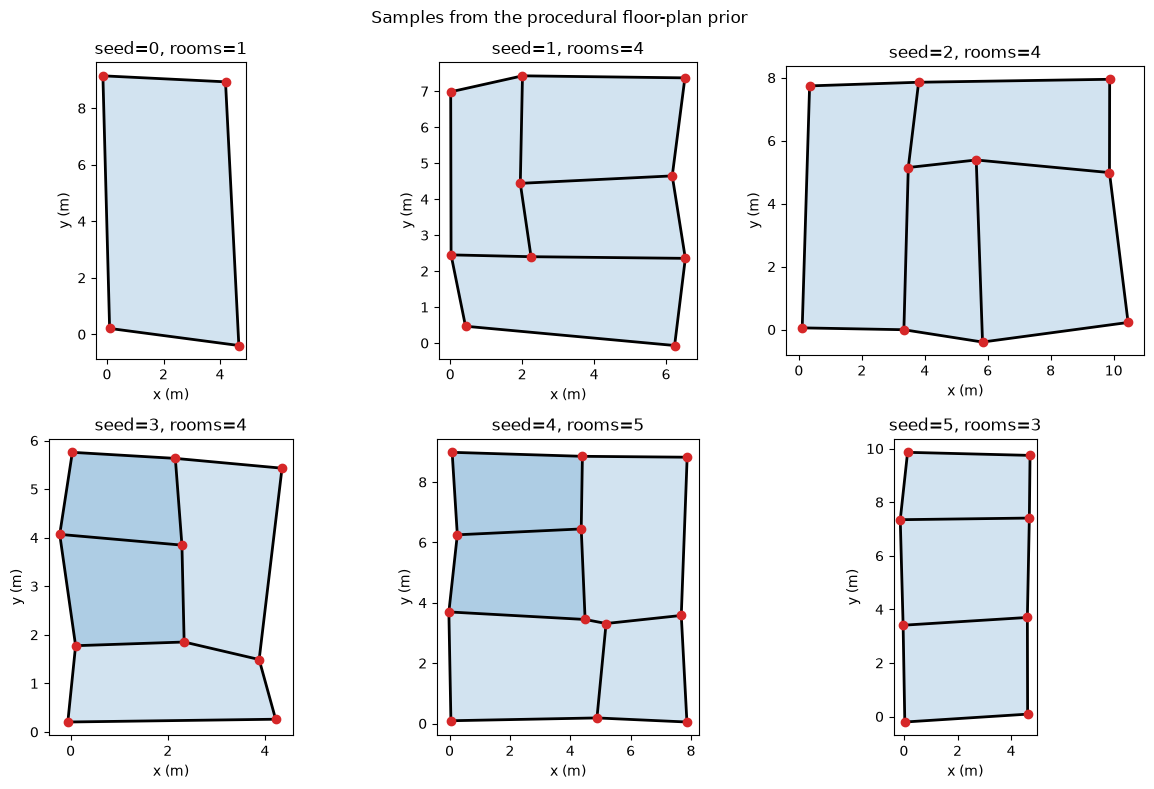

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, ax in enumerate(axes.flat):
    fp = prior.sample(jax.random.PRNGKey(i))
    plot_floor_plan(fp, ax=ax)
    ax.set_title(f"seed={i}, rooms={len(fp.cycles())}")
fig.suptitle("Samples from the procedural floor-plan prior")
fig.tight_layout()
plt.show()

## `log P(G)` and its five terms

Each term is individually available as a plain function for inspection; `Prior.log_prob` sums whichever terms `config.use_*` enables.

In [4]:
floor_plan = prior.sample(jax.random.PRNGKey(0))

print("log P(G) terms:")
print(f"  complexity:          {complexity_log_prob(floor_plan, config.lambda_complexity):.3f}")
print(
    f"  orthogonality:       {orthogonality_log_prob(floor_plan, config.lambda_orthogonality):.3f}"
)
print(f"  min length:          {min_length_log_prob(floor_plan, config.min_segment_length):.3f}")
print(
    f"  junction regularity: {junction_regularity_log_prob(floor_plan, config.lambda_junction):.3f}"
)
print(
    "  room size:           "
    f"{room_size_log_prob(floor_plan, config.room_area_mean, config.room_area_std):.3f}"
)
print(f"  total log P(G):      {prior.log_prob(floor_plan):.3f}")

log P(G) terms:
  complexity:          -0.400
  orthogonality:       -0.258
  min length:          0.000
  junction regularity: -1.030
  room size:           -8.097
  total log P(G):      -9.784


## Ablation: switching terms on and off

Every term is independently switchable via `PriorConfig`'s `use_*` flags, for ablation studies. `dataclasses.replace` makes a modified copy of the (frozen) config.

In [5]:
no_room_size_config = dataclasses.replace(config, use_room_size=False)

print("with room-size term:   ", prior.log_prob(floor_plan))
print("without room-size term:", Prior(no_room_size_config).log_prob(floor_plan))

with room-size term:    -9.784234783523038
without room-size term: -1.6876734609273476


## Effect of `orthogonality_perturbation_sigma`

The sampler jitters junctions after BSP subdivision; the jitter scale is derived from this angular sigma (radians) times each junction's mean incident wall length.

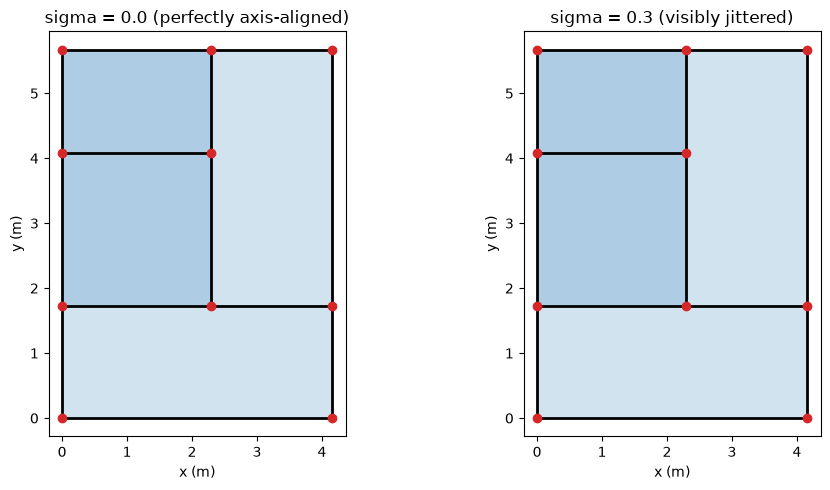

In [14]:
no_pert_config = dataclasses.replace(config, orthogonality_perturbation_sigma=0.0)
high_pert_config = dataclasses.replace(config, orthogonality_perturbation_sigma=1.)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
plot_floor_plan(sample(jax.random.PRNGKey(3), no_pert_config), ax=axes[0])
axes[0].set_title("sigma = 0.0 (perfectly axis-aligned)")
plot_floor_plan(sample(jax.random.PRNGKey(3), high_pert_config), ax=axes[1])
axes[1].set_title("sigma = 0.3 (visibly jittered)")
fig.tight_layout()
plt.show()

## Effect of `room_count_rate`

The Poisson rate controlling how many rooms the sampler targets before the BSP subdivision stops (subject to `max_bsp_depth`).

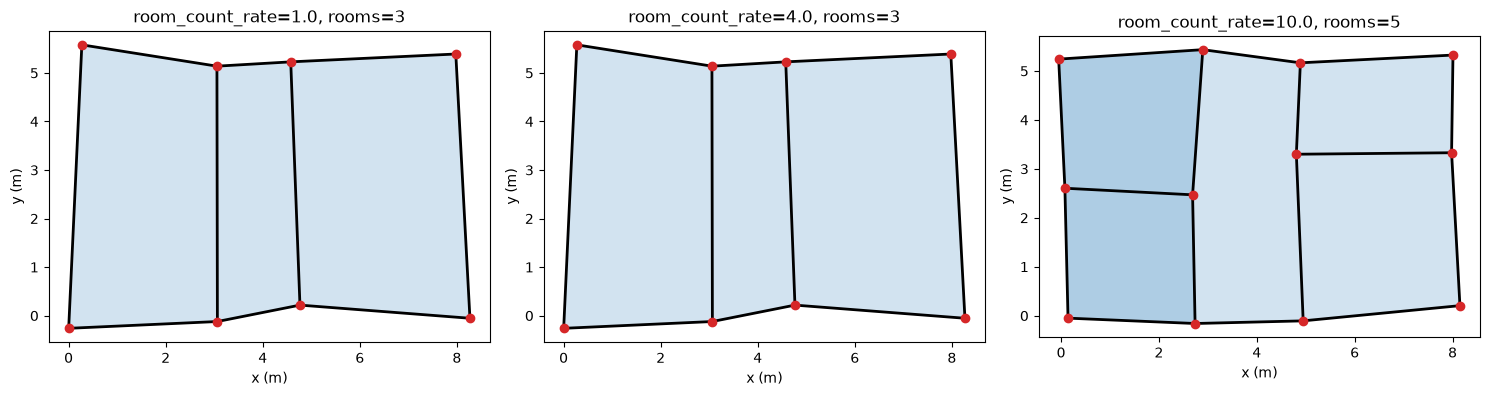

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, rate in zip(axes, [1.0, 4.0, 10.0]):
    cfg = dataclasses.replace(config, room_count_rate=rate)
    fp = sample(jax.random.PRNGKey(7), cfg)
    plot_floor_plan(fp, ax=ax)
    ax.set_title(f"room_count_rate={rate}, rooms={len(fp.cycles())}")
fig.tight_layout()
plt.show()

This exercises the full prior: the five `log P(G)` terms, their combination and ablation, and the procedural sampler's response to its configuration. Next: `04_rjmcmc_synthetic.ipynb`.